# 04. Análise exploratória

Relação das variáveis com o consumo, com dados até 2025.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from funcoes.nomes import JANELAS, rotulo

pd.set_option("display.max_rows", 90, "display.max_columns", 30, "display.width", 180, "display.max_colwidth", 60)
CLAUDE = Path("..")
SILVER, GOLD = CLAUDE / "dados" / "silver", CLAUDE / "dados" / "gold"
FIGURAS = CLAUDE / "resultados" / "figuras"
CORTE = "2025-12-31"

SUPERFICIE, TEXTO2, GRADE = "#fcfcfb", "#52514e", "#e6e5e0"
AZUL, LARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE, "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2, "axes.grid": True, "grid.color": GRADE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10,
})

fato = pd.read_parquet(SILVER / "silver_fato_diaria.parquet")
dias = pd.read_parquet(SILVER / "silver_dias_classificados.parquet")
t1 = pd.read_parquet(GOLD / "gold_t1.parquet")
t2 = pd.read_parquet(GOLD / "gold_t2.parquet")
servidos = fato[fato["no_escopo"] & fato["tem_consumo"]].merge(dias[["data", "usar_no_treino", "tratamento", "razao_referencia"]], on="data").sort_values("data").reset_index(drop=True)
print(f"Dias com consumo: {len(servidos)} | no treino até {CORTE}: {(servidos['usar_no_treino'] & (servidos['data'] <= CORTE)).sum()}")

Dias com consumo: 656 | no treino até 2025-12-31: 485


## 1. Defasagens, médias e dispersão

As defasagens abaixo usam o consumo até o dia anterior. **Esse é o cenário ideal, não o da sexta-feira de emissão**: para prever uma quarta-feira, o consumo de terça ainda não existe. A seção 2 mostra o que sobra quando só se usa o que era conhecido.

In [2]:
s = servidos.set_index("data")["consumo"]
L = pd.DataFrame({"consumo": servidos["consumo"].values}, index=servidos["data"])
for k in (1, 2, 3, 5, 10):
    L[f"lag_{k}_dias_servidos"] = s.shift(k).values
for semanas in (1, 2, 3, 4):
    L[f"mesmo_dia_{semanas}_semana(s)_antes"] = s.reindex(s.index - pd.Timedelta(days=7 * semanas)).values
anterior = s.shift(1)
for j in (5, 10, 20):
    L[f"media_movel_{j}d"] = anterior.rolling(j).mean().values
    L[f"mediana_movel_{j}d"] = anterior.rolling(j).median().values
for j in (5, 10):
    L[f"desvio_padrao_{j}d"] = anterior.rolling(j).std().values
L["minimo_5d"] = anterior.rolling(5).min().values
L["maximo_5d"] = anterior.rolling(5).max().values

base = L[servidos.set_index("data")["usar_no_treino"] & (L.index <= CORTE)]
linhas = []
for coluna in L.columns.drop("consumo"):
    d = base[["consumo", coluna]].dropna()
    por_ano = d.groupby(d.index.year).apply(lambda g: g["consumo"].corr(g[coluna]))
    linhas.append({"variavel": coluna, "dias": len(d), "pearson": d["consumo"].corr(d[coluna]),
                   "spearman": d["consumo"].corr(d[coluna], method="spearman"), "pearson_medio_por_ano": por_ano.mean()})
lags = pd.DataFrame(linhas).sort_values("pearson", ascending=False).set_index("variavel").round(3)
lags.rename(index=rotulo, columns=rotulo)

,Dias analisados,Relação linear com o consumo,Relação com o consumo (ordem dos valores),"Relação com o consumo, média por ano"
variavel,,,,
Média dos 5 dias anteriores,480,0.661,0.657,0.435
Maior consumo nos últimos 5 dias,480,0.649,0.670,0.370
"Mesmo dia, semana passada",400,0.640,0.665,0.434
Consumo do dia anterior,484,0.624,0.592,0.471
Média dos 10 dias anteriores,475,0.624,0.617,0.352
Valor central dos 5 dias anteriores,480,0.619,0.623,0.373
"Mesmo dia, há 2 semanas",368,0.609,0.641,0.366
Valor central dos 10 dias anteriores,475,0.586,0.592,0.280
Menor consumo nos últimos 5 dias,480,0.573,0.547,0.445


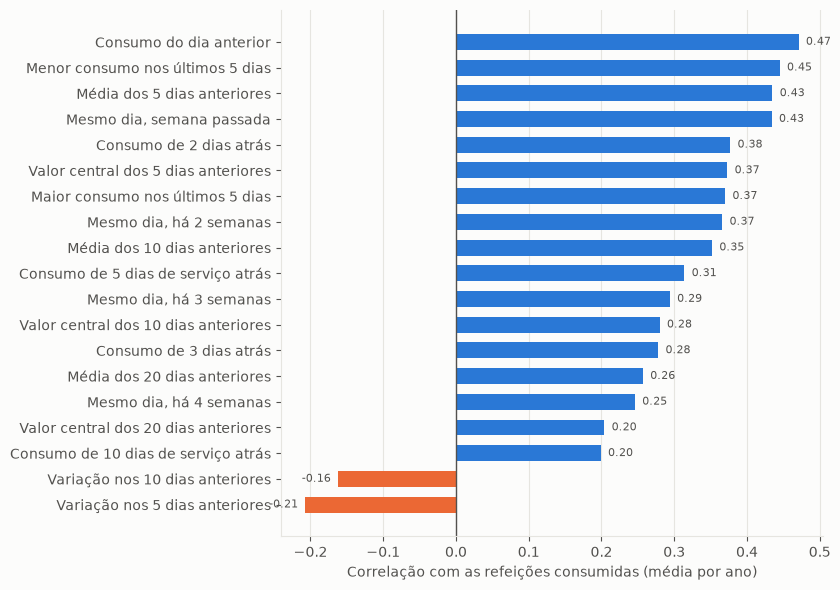

In [3]:
ordem = lags.sort_values("pearson_medio_por_ano")
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(ordem.index.map(rotulo), ordem["pearson_medio_por_ano"], height=0.62, color=[AZUL if v >= 0 else LARANJA for v in ordem["pearson_medio_por_ano"]])
ax.axvline(0, color=TEXTO2, linewidth=1)
ax.set_xlabel("Correlação com as refeições consumidas (média por ano)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(ordem["pearson_medio_por_ano"]):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=TEXTO2)
fig.tight_layout()
fig.savefig(FIGURAS / "04_correlacao_defasagens.png", dpi=200)
plt.show()

## 2. O que realmente se sabe na sexta-feira

O consumo de ontem não está disponível para o algoritmo na sexta-feira do planejamento. Esta tabela compara o cenário ideal com o que realmente se sabia, nas mesmas datas. A diferença mostra o custo real de prever com antecedência.

In [4]:
def correlacoes_emissao(g, nome):
    d = g[g["usar_no_treino"] & (g["data"] <= CORTE)].set_index("data")
    colunas = ("nivel_base", "nivel_exponencial", "nivel_10d", "nivel_20d", "nivel_mesmo_dia", "nivel_bloco_atual", "ultimo_consumo", "media_5d", "mediana_5d", "media_10d", "media_20d",
               "mesmo_dia_ha_1_ocorrencias", "mesmo_dia_ha_2_ocorrencias", "mesmo_dia_ha_3_ocorrencias", "mesmo_dia_ha_4_ocorrencias", "desvio_5d", "desvio_10d", "minimo_5d", "maximo_5d")
    saida = {c: d["consumo"].corr(d[c]) for c in colunas}
    d = d.join(L[["lag_1_dias_servidos", "media_movel_5d"]])
    saida["ideal: consumo do dia anterior"] = d["consumo"].corr(d["lag_1_dias_servidos"])
    saida["ideal: média móvel 5d"] = d["consumo"].corr(d["media_movel_5d"])
    return pd.Series(saida, name=nome)

pd.concat([correlacoes_emissao(t1, JANELAS["t1"]), correlacoes_emissao(t2, JANELAS["t2"])], axis=1).round(3).rename(index=rotulo)

,Preparo (semana seguinte),Compras (daqui a duas semanas)
Consumo de referência,0.613,0.537
"Consumo recente, com mais peso nos últimos dias",0.580,0.516
Consumo de referência dos últimos 10 dias,0.557,0.484
Consumo de referência dos últimos 20 dias,0.521,0.455
Consumo de referência neste dia da semana,0.594,0.526
Consumo de referência neste período de aulas,0.593,0.560
Último consumo conhecido,0.441,0.370
Média dos últimos 5 dias,0.585,0.529
Valor central dos últimos 5 dias,0.557,0.512
Média dos últimos 10 dias,0.564,0.499


### Informações repetidas

Duas medidas quase idênticas não acrescentam informação. Pares com relação acima de 0,95 indicam que basta manter uma delas.

In [5]:
nivel = ["nivel_base", "nivel_exponencial", "nivel_10d", "nivel_20d", "nivel_mesmo_dia", "ultimo_consumo", "media_5d", "mediana_5d", "media_10d", "media_20d", "mesmo_dia_ha_1_ocorrencias", "mesmo_dia_ha_2_ocorrencias"]
matriz = t1.loc[t1["usar_no_treino"] & (t1["data"] <= CORTE), nivel].corr().rename(index=rotulo, columns=rotulo)
pares = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print("Pares acima de 0,95:", (pares > 0.95).sum())
pares.head(8).round(3)

Pares acima de 0,95: 8


Consumo de referência dos últimos 20 dias        Média dos últimos 20 dias                    0.986
Consumo de referência dos últimos 10 dias        Média dos últimos 10 dias                    0.985
Consumo recente, com mais peso nos últimos dias  Média dos últimos 5 dias                     0.984
                                                 Média dos últimos 10 dias                    0.982
Média dos últimos 5 dias                         Valor central dos últimos 5 dias             0.964
Consumo recente, com mais peso nos últimos dias  Consumo de referência dos últimos 10 dias    0.962
Média dos últimos 10 dias                        Média dos últimos 20 dias                    0.961
Média dos últimos 5 dias                         Média dos últimos 10 dias                    0.955
dtype: float64

## 3. O que faz um dia ficar acima ou abaixo da referência

Descontado o consumo de referência, sobra o efeito do calendário, do cardápio e do clima. A comparação usa o que se sabia na sexta-feira do planejamento do preparo.

In [6]:
d = t1[t1["usar_no_treino"] & (t1["data"] <= CORTE) & t1["alvo_relativo"].notna()].copy()
for dia in ["seg", "ter", "qua", "qui", "sex"]:
    d[f"dia_{dia}"] = d[f"dia_{dia}"].astype(float)
for prot in ["frango", "bovina", "suina", "peixe", "feijoada", "mista"]:
    d[f"proteina_{prot}"] = d["proteina"].eq(prot).astype(float).where(d["proteina"].notna())
for prep in d["preparo"].dropna().unique():
    d[f"preparo_{prep}"] = d["preparo"].eq(prep).astype(float).where(d["preparo"].notna())
grupos = {
    "Consumo recente": ["tendencia_nivel", "dispersao_recente", "coef_variacao_10d", "idade_informacao_dias", "dias_observados_no_bloco"] + [c for c in d.columns if c.startswith("rel_")],
    "Calendário": ["dia_seg", "dia_ter", "dia_qua", "dia_qui", "dia_sex", "dias_ate_fim_bloco", "dias_desde_inicio_bloco", "semana_do_bloco", "fim_de_bloco", "inicio_de_bloco",
                   "vespera_de_pausa", "pos_pausa", "dias_sem_aula_antes", "dias_letivos_na_semana", "evento_especial", "efeito_evento"],
    "Cardápio": ["efeito_proteina", "efeito_preparo", "efeito_prato"] + [c for c in d.columns if c.startswith(("proteina_", "preparo_"))],
    "Clima previsto": ["previsao_chuva_mm", "previsao_chuva_manha_mm", "previsao_chuva_acum3d_mm", "previsao_temp_max"],
    "Clima que ocorreu": ["oraculo_chuva_mm", "oraculo_chuva_horas", "oraculo_temp_max", "oraculo_vento_max"],
}
linhas = []
for grupo, colunas in grupos.items():
    for c in colunas:
        v = d[c].astype(float)
        ok = v.notna()
        linhas.append({"grupo": grupo, "variavel": c, "dias": int(ok.sum()), "pearson": d.loc[ok, "alvo_relativo"].corr(v[ok]), "spearman": d.loc[ok, "alvo_relativo"].corr(v[ok], method="spearman")})
rel = pd.DataFrame(linhas)
rel["forca"] = rel["spearman"].abs()
rel["nome"] = rel["variavel"].map(rotulo)
rel.sort_values("forca", ascending=False)[["grupo", "nome", "dias", "pearson", "spearman"]].round(3).head(45).reset_index(drop=True).rename(columns=rotulo)

,grupo,nome,Dias analisados,Relação linear com o consumo,Relação com o consumo (ordem dos valores)
0,Calendário,Últimos dias do período de aulas,473,-0.392,-0.272
1,Calendário,Dia com evento fora da rotina,473,-0.161,-0.185
2,Calendário,Semana dentro do período de aulas,473,-0.246,-0.176
3,Consumo recente,Dias já registrados neste período de aulas,473,-0.252,-0.166
4,Consumo recente,Mesmo dia da semana comparado à referência,473,0.186,0.159
5,Calendário,Primeiros dias do período de aulas,473,-0.172,-0.145
6,Calendário,Dias de aula até o fim do período,473,0.311,0.145
7,Clima previsto,Chuva prevista em 3 dias (mm),307,0.186,0.140
8,Calendário,Dias sem aula logo antes,473,-0.068,-0.129
9,Calendário,Volta depois de dia sem aula,473,-0.113,-0.129


                   maior_correlacao  mediana
grupo                                       
Calendário                    0.272    0.106
Consumo recente               0.166    0.084
Clima previsto                0.140    0.057
Clima que ocorreu             0.085    0.037
Cardápio                      0.075    0.038


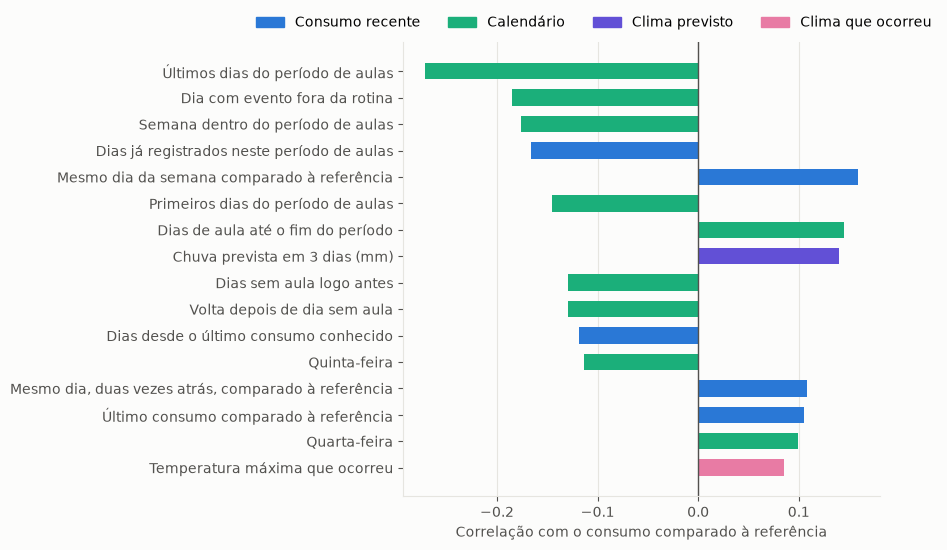

In [7]:
print(rel.groupby("grupo")["forca"].agg(maior_correlacao="max", mediana="median").round(3).sort_values("maior_correlacao", ascending=False).to_string())
top = rel.sort_values("forca", ascending=False).head(16).iloc[::-1]
cores = {"Consumo recente": AZUL, "Calendário": AQUA, "Cardápio": LARANJA, "Clima previsto": "#6250d6", "Clima que ocorreu": "#e87ba4"}
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(top["nome"], top["spearman"], height=0.62, color=[cores[g] for g in top["grupo"]])
ax.axvline(0, color=TEXTO2, linewidth=1)
ax.set_xlabel("Correlação com o consumo comparado à referência")
ax.grid(axis="y", visible=False)
presentes = [g for g in cores if g in set(top["grupo"])]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cores[g]) for g in presentes], labels=presentes, frameon=False, loc="lower center", bbox_to_anchor=(0.4, 1.0), ncol=len(presentes))
fig.tight_layout()
fig.savefig(FIGURAS / "05_correlacao_consumo_relativo.png", dpi=200)
plt.show()

## 4. Quanto o consumo muda

A relação mostra a direção; esta tabela mostra o tamanho. O valor 1,00 significa consumo igual à referência, e 0,90 significa 10% abaixo.

In [8]:
def efeito(coluna):
    return d.groupby(coluna, observed=True)["alvo_relativo"].agg(dias="size", relativo_mediano="median").round(3).rename(columns=rotulo).rename_axis(rotulo(coluna))

In [9]:
DIAS_SEMANA = dict(enumerate(["Segunda", "Terça", "Quarta", "Quinta", "Sexta"]))
d["dia_semana"] = d["dia_semana"].map(DIAS_SEMANA)
SIM_NAO = {True: "Sim", False: "Não"}
for coluna in ("fim_de_bloco", "inicio_de_bloco", "vespera_de_pausa", "pos_pausa"):
    d[coluna] = d[coluna].map(SIM_NAO)

d["faixa_chuva_prevista"] = pd.cut(d["previsao_chuva_mm"], [-1, 1, 5, 15, 500], labels=["até 1 mm", "1 a 5 mm", "5 a 15 mm", "15 mm ou mais"])
d["faixa_chuva_real"] = pd.cut(d["oraculo_chuva_mm"], [-1, 1, 5, 15, 500], labels=["até 1 mm", "1 a 5 mm", "5 a 15 mm", "15 mm ou mais"])
d["faixa_temp_real"] = pd.cut(d["oraculo_temp_max"], [0, 22, 26, 30, 50], labels=["até 22 °C", "22 a 26 °C", "26 a 30 °C", "acima de 30 °C"])
NOMES_FAIXAS = {"faixa_chuva_prevista": "Chuva prevista no dia", "faixa_chuva_real": "Chuva que ocorreu no dia", "faixa_temp_real": "Temperatura máxima que ocorreu"}
for coluna in ["dia_semana", "fim_de_bloco", "inicio_de_bloco", "vespera_de_pausa", "pos_pausa", "proteina", "preparo", *NOMES_FAIXAS]:
    print(f"\n{NOMES_FAIXAS.get(coluna, rotulo(coluna))}")
    print(efeito(coluna).rename_axis(None).to_string())


Dia da semana
         Dias analisados  Consumo comparado à referência
Quarta                97                           1.016
Quinta                95                           0.959
Segunda               96                           1.007
Sexta                 92                           0.989
Terça                 93                           0.995

Últimos dias do período de aulas
     Dias analisados  Consumo comparado à referência
Não              457                           1.006
Sim               16                           0.462

Primeiros dias do período de aulas
     Dias analisados  Consumo comparado à referência
Não              451                           1.004
Sim               22                           0.856

Véspera de dia sem aula
     Dias analisados  Consumo comparado à referência
Não              450                           1.002
Sim               23                           0.983

Volta depois de dia sem aula
     Dias analisados  Consumo comparado à

In [10]:
ev = d.groupby("evento_tipo")["alvo_relativo"].agg(dias="size", relativo_mediano="median").round(3)
ev.index = ev.index.str.replace("_", " ").str.capitalize()
ev[ev["dias"] >= 3].sort_values("relativo_mediano").rename(columns=rotulo).rename_axis("Evento do calendário")

,Dias analisados,Consumo comparado à referência
Evento do calendário,,
Inicio etapa,4,0.782
Encerramento etapa,9,0.801
Semana ciencia tecnologia,8,0.803
Semana consciencia negra,5,0.866
Conselho classe,3,0.876
Reuniao familias,7,0.903
Atividade cultural,11,0.905
Prazo administrativo,11,0.978
Formacao,7,0.983


In [11]:
from funcoes.nomes import PREPAROS, PROTEINAS
combinacao = t1.loc[d.index, "proteina"].map(PROTEINAS) + " / " + t1.loc[d.index, "preparo"].map(PREPAROS).str.lower()
pratos = d[d["sem_cardapio"].eq(False)].groupby(combinacao)["alvo_relativo"].agg(dias="size", relativo_mediano="median")
pratos = pratos[pratos["dias"] >= 6].sort_values("relativo_mediano").round(3)
pd.concat([pratos.head(5), pratos.tail(5)]).rename(columns=rotulo).rename_axis("Proteína e preparo")

,Dias analisados,Consumo comparado à referência
Proteína e preparo,,
Peixe / empanado ou à milanesa,15,0.897
Carne bovina / cremoso ou ensopado,11,0.909
Frango / cremoso ou ensopado,32,0.935
Frango / churrasco ou espeto,6,0.939
Carne bovina / ao molho ou refogado,39,0.976
Carne bovina / cozido ou refogado,49,1.010
Frango / empanado ou à milanesa,21,1.011
Frango / assado,23,1.037
Frango / grelhado,20,1.043


## 5. Que tipo de chuva acompanha o consumo

A chuva do dia inteiro quase não aparece. Aqui a comparação usa todos os dias com consumo, inclusive os atípicos, e separa a chuva realizada da manhã e a acumulada. A chuva da manhã existe desde 2024.

In [12]:
horario = pd.read_csv(CLAUDE / "dados" / "bronze" / "clima_previsoes" / "previous_runs_horario.csv", sep=";", parse_dates=["time"])
manha = horario[horario["time"].dt.hour.between(6, 13)].groupby(horario["time"].dt.normalize())["precipitation"].sum().rename("chuva_manha_mm")
clima = fato.sort_values("data").assign(chuva_acum3d_mm=lambda f: f["chuva_mm"].rolling(3).sum())[["data", "chuva_acum3d_mm"]]
chuva = dias.dropna(subset=["razao_referencia"]).merge(clima, on="data").merge(manha, left_on="data", right_index=True, how="left")
chuva = chuva[chuva["data"] <= CORTE]
for coluna, cortes in (("chuva_manha_mm", [-1, 0, 2, 5, 10, 200]), ("chuva_acum3d_mm", [-1, 5, 20, 40, 500])):
    tabela = chuva.groupby(pd.cut(chuva[coluna], cortes), observed=True)["razao_referencia"].agg(dias="size", razao_mediana="median", dias_baixos=lambda v: (v < 0.6).mean())
    tabela.columns = ["Dias analisados", "Consumo comparado à referência", "Parcela de dias baixos"]
    print({"chuva_manha_mm": "Chuva de manhã, das 6h às 13h (mm)", "chuva_acum3d_mm": "Chuva acumulada em 3 dias (mm)"}[coluna])
    print(tabela.round(3).rename_axis(None).to_string()); print()

Chuva de manhã, das 6h às 13h (mm)
           Dias analisados  Consumo comparado à referência  Parcela de dias baixos
(-1, 0]                186                           1.009                   0.043
(0, 2]                 103                           1.009                   0.078
(2, 5]                  17                           0.931                   0.000
(5, 10]                  9                           0.979                   0.222
(10, 200]                4                           0.802                   0.000

Chuva acumulada em 3 dias (mm)
           Dias analisados  Consumo comparado à referência  Parcela de dias baixos
(-1, 5]                297                           1.008                   0.051
(5, 20]                112                           1.004                   0.062
(20, 40]                71                           1.005                   0.085
(40, 500]               12                           0.858                   0.333



## 6. Leitura

As conclusões numéricas ficam nas tabelas acima. O que orienta a próxima etapa:

- O consumo recente define o patamar de refeições, mas a sexta-feira só conhece parte dele.
- Descontado o consumo de referência, o calendário concentra a maior parte do sinal; cardápio e clima entram como ajustes menores, a confirmar pelos cenários.
- A utilidade real de cada grupo será medida nos cenários: uma informação só permanece se reduzir o erro em datas que o modelo ainda não viu.